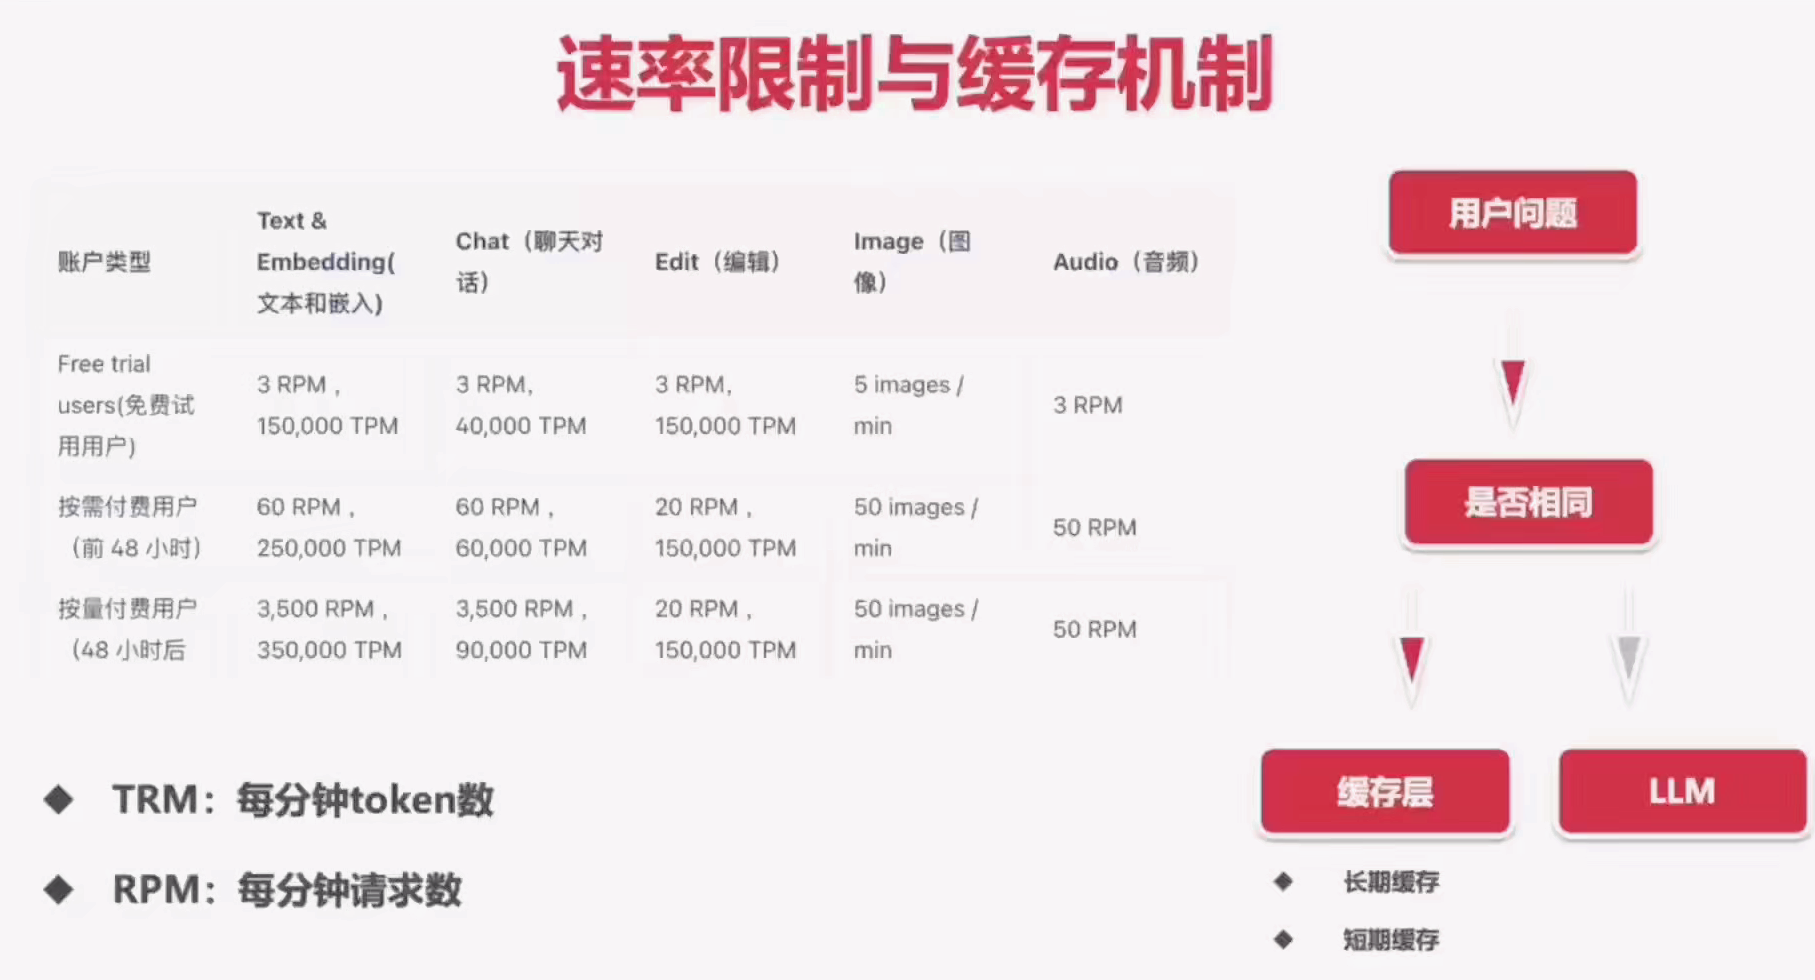

In [15]:
# 速率限制
from langchain_deepseek import ChatDeepSeek
from langchain_core.rate_limiters import InMemoryRateLimiter
import time
import os
from dotenv import load_dotenv

load_dotenv()

rate_limiter = InMemoryRateLimiter(
    requests_per_second=5,  # 每个时间间隔内允许的请求次数
    check_every_n_seconds=0.1,  # 每n秒检查一次速率限制
    max_bucket_size=10  # 最大令牌桶大小
)

# 定义模型调用
model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4.1-Flash",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
    rate_limiter=rate_limiter, 
)

# 使用计时器来计算
# 每次请求的时间间隔
for _ in range(5):
    tic = time.time()
    model.invoke("hello")
    toc = time.time()
    print(toc - tic)
    print(f"请求耗时: {toc - tic:.2f} 秒")


1.8705196380615234
请求耗时: 1.87 秒
1.5121731758117676
请求耗时: 1.51 秒
1.2797529697418213
请求耗时: 1.28 秒
2.4752228260040283
请求耗时: 2.48 秒
4.621004104614258
请求耗时: 4.62 秒
